In [1]:
import pandas as pd
import numpy as np

# Create reproducible synthetic data
np.random.seed(42)

# Generate 2,000 dates for each of 2 products
dates = pd.date_range(start="2024-01-01", periods=2000, freq="D")

data = []

for date in dates:
    post_period = int(date >= pd.Timestamp("2025-05-15"))

    # Treatment product: price increases after intervention
    treatment_price = 500 if post_period == 0 else 540
    treatment_units = max(
        1, int(np.random.normal(25 - 2 * post_period, 3))
    )

    data.append([
        date, "Earphones", "Audio", treatment_price,
        treatment_units, post_period, 1, 0, post_period,
        treatment_price * treatment_units
    ])

    # Control product: price remains unchanged
    control_price = 200
    control_units = max(1, int(np.random.normal(40, 4)))

    data.append([
        date, "USB Cable", "Cables", control_price,
        control_units, 0, 0, 1, post_period,
        control_price * control_units
    ])

# Create DataFrame
columns = [
    "Date", "Product", "Category", "Price", "Units_Sold",
    "Price_Change", "Treatment_Group", "Control_Group",
    "Post_Period", "Revenue"
]

df = pd.DataFrame(data, columns=columns)

# Display results
print("Dataset created successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset created successfully!
Dataset shape: (4000, 10)


,Date,Product,Category,Price,Units_Sold,Price_Change,Treatment_Group,Control_Group,Post_Period,Revenue
0,2024-01-01,Earphones,Audio,500,26,0,1,0,0,13000
1,2024-01-01,USB Cable,Cables,200,39,0,0,1,0,7800
2,2024-01-02,Earphones,Audio,500,26,0,1,0,0,13000
3,2024-01-02,USB Cable,Cables,200,46,0,0,1,0,9200
4,2024-01-03,Earphones,Audio,500,24,0,1,0,0,12000


In [2]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check dataset information
print("\nDataset Information:")
df.info()

Missing Values:
Date               0
Product            0
Category           0
Price              0
Units_Sold         0
Price_Change       0
Treatment_Group    0
Control_Group      0
Post_Period        0
Revenue            0
dtype: int64

Duplicate Rows:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             4000 non-null   datetime64[ns]
 1   Product          4000 non-null   object        
 2   Category         4000 non-null   object        
 3   Price            4000 non-null   int64         
 4   Units_Sold       4000 non-null   int64         
 5   Price_Change     4000 non-null   int64         
 6   Treatment_Group  4000 non-null   int64         
 7   Control_Group    4000 non-null   int64         
 8   Post_Period      4000 non-null   int64         
 9   Revenue          4000 non

In [3]:
# Count treatment and control group records

print("Treatment Group:")
print(df["Treatment_Group"].value_counts())

print("\nControl Group:")
print(df["Control_Group"].value_counts())

print("\nAverage Units Sold by Product:")
print(df.groupby("Product")["Units_Sold"].mean())

print("\nAverage Revenue by Product:")
print(df.groupby("Product")["Revenue"].mean())

Treatment Group:
Treatment_Group
1    2000
0    2000
Name: count, dtype: int64

Control Group:
Control_Group
0    2000
1    2000
Name: count, dtype: int64

Average Units Sold by Product:
Product
Earphones    23.0275
USB Cable    39.6035
Name: Units_Sold, dtype: float64

Average Revenue by Product:
Product
Earphones    12189.95
USB Cable     7920.70
Name: Revenue, dtype: float64


In [4]:
# Compare average units sold before and after intervention

sales_comparison = df.groupby(
    ["Product", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Units Sold Before and After Intervention:")
print(sales_comparison)

Average Units Sold Before and After Intervention:
Post_Period      0          1
Product                      
Earphones    24.49  22.540000
USB Cable    39.64  39.591333


In [5]:
# Calculate average sales before and after intervention

comparison = df.groupby(
    ["Treatment_Group", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Units Sold:")
print(comparison)

# Calculate Difference-in-Differences

treatment_change = comparison.loc[1, 1] - comparison.loc[1, 0]

control_change = comparison.loc[0, 1] - comparison.loc[0, 0]

did_effect = treatment_change - control_change

print("\nTreatment Group Change:", round(treatment_change, 2))
print("Control Group Change:", round(control_change, 2))
print("Difference-in-Differences Effect:", round(did_effect, 2))

Average Units Sold:
Post_Period          0          1
Treatment_Group                  
0                39.64  39.591333
1                24.49  22.540000

Treatment Group Change: -1.95
Control Group Change: -0.05
Difference-in-Differences Effect: -1.9


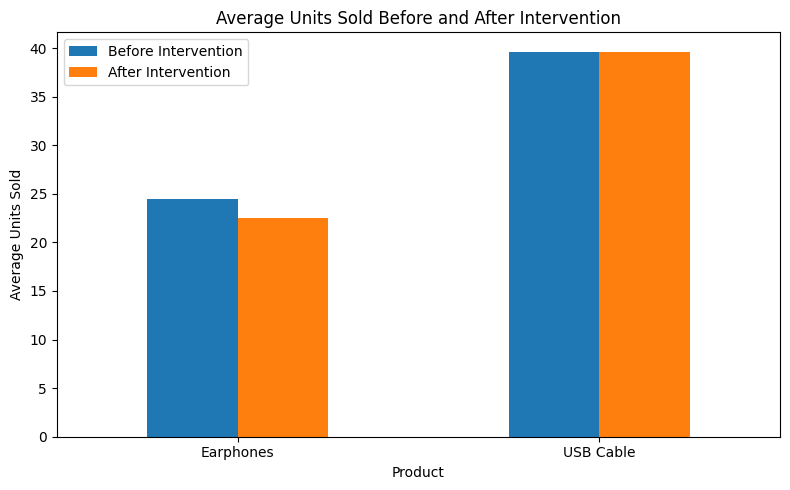

In [6]:
import matplotlib.pyplot as plt

sales_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Units Sold Before and After Intervention")
plt.xlabel("Product")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.legend(["Before Intervention", "After Intervention"])
plt.tight_layout()
plt.show()

In [7]:
# Save the dataset as a CSV file

df.to_csv("Pricing_Dataset_4000_Rows.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [8]:
from google.colab import files

files.download("Pricing_Dataset_4000_Rows.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import pandas as pd

df = pd.read_csv("Pricing_Dataset_4000_Rows.csv")

print(df.head())

         Date    Product Category  Price  Units_Sold  Price_Change  \
0  2024-01-01  Earphones    Audio    500          26             0   
1  2024-01-01  USB Cable   Cables    200          39             0   
2  2024-01-02  Earphones    Audio    500          26             0   
3  2024-01-02  USB Cable   Cables    200          46             0   
4  2024-01-03  Earphones    Audio    500          24             0   

   Treatment_Group  Control_Group  Post_Period  Revenue  
0                1              0            0    13000  
1                0              1            0     7800  
2                1              0            0    13000  
3                0              1            0     9200  
4                1              0            0    12000  


In [3]:
print(df.shape)
print(df.columns)

(4000, 10)
Index(['Date', 'Product', 'Category', 'Price', 'Units_Sold', 'Price_Change',
       'Treatment_Group', 'Control_Group', 'Post_Period', 'Revenue'],
      dtype='object')


In [4]:

import pandas as pd

# Convert Date column into date format
df["Date"] = pd.to_datetime(df["Date"])

# Compare sales and revenue before and after the intervention
analysis = df.groupby(
    ["Product", "Post_Period"]
).agg(
    Average_Units=("Units_Sold", "mean"),
    Total_Units=("Units_Sold", "sum"),
    Average_Revenue=("Revenue", "mean"),
    Total_Revenue=("Revenue", "sum")
).reset_index()

print(analysis)


     Product  Post_Period  Average_Units  Total_Units  Average_Revenue  \
0  Earphones            0      24.490000        12245     12245.000000   
1  Earphones            1      22.540000        33810     12171.600000   
2  USB Cable            0      39.640000        19820      7928.000000   
3  USB Cable            1      39.591333        59387      7918.266667   

   Total_Revenue  
0        6122500  
1       18257400  
2        3964000  
3       11877400  


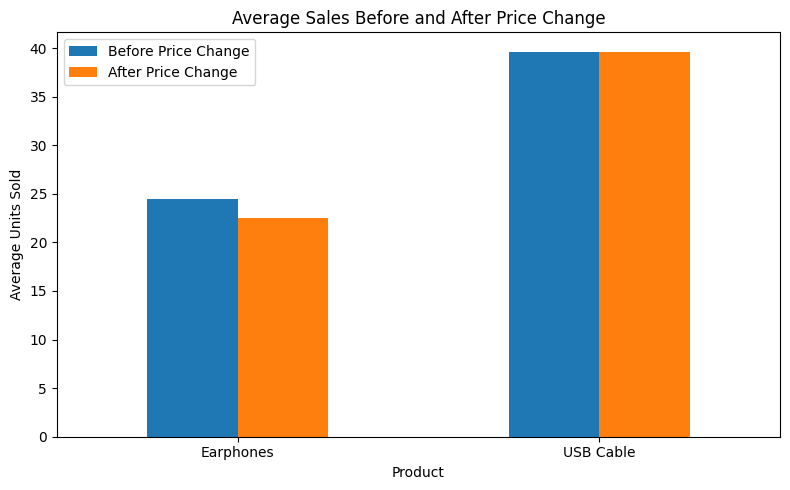

In [5]:
import matplotlib.pyplot as plt

sales = df.groupby(
    ["Product", "Post_Period"]
)["Units_Sold"].mean().unstack()

sales.plot(kind="bar", figsize=(8, 5))

plt.title("Average Sales Before and After Price Change")
plt.xlabel("Product")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.legend(["Before Price Change", "After Price Change"])
plt.tight_layout()
plt.show()

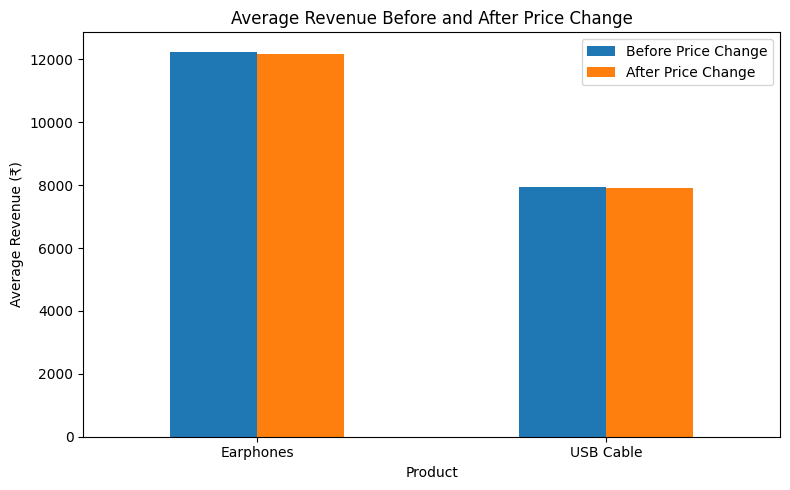

In [6]:
revenue = df.groupby(
    ["Product", "Post_Period"]
)["Revenue"].mean().unstack()

revenue.plot(kind="bar", figsize=(8, 5))

plt.title("Average Revenue Before and After Price Change")
plt.xlabel("Product")
plt.ylabel("Average Revenue (₹)")
plt.xticks(rotation=0)
plt.legend(["Before Price Change", "After Price Change"])
plt.tight_layout()
plt.show()

In [7]:
# Calculate average sales for treatment and control groups

did_data = df.groupby(
    ["Treatment_Group", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Sales Before and After Price Change:")
print(did_data)

Average Sales Before and After Price Change:
Post_Period          0          1
Treatment_Group                  
0                39.64  39.591333
1                24.49  22.540000


In [8]:
# Treatment group sales change
treatment_change = did_data.loc[1, 1] - did_data.loc[1, 0]

# Control group sales change
control_change = did_data.loc[0, 1] - did_data.loc[0, 0]

# Difference-in-Differences
did_effect = treatment_change - control_change

print("Treatment Group Change:", treatment_change)
print("Control Group Change:", control_change)
print("DiD Effect:", did_effect)

Treatment Group Change: -1.9499999999999993
Control Group Change: -0.0486666666666693
DiD Effect: -1.90133333333333


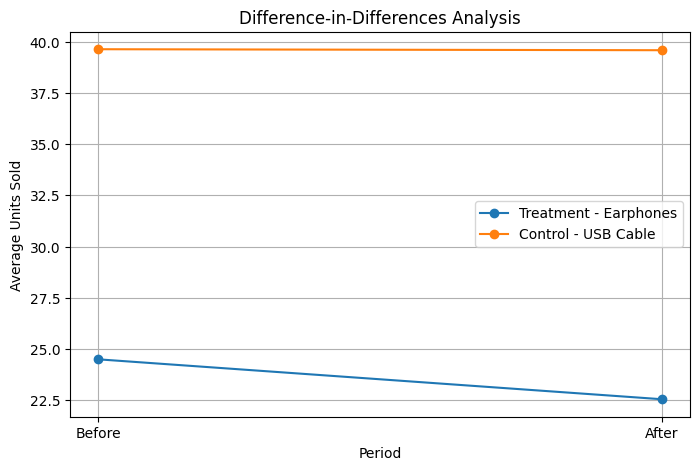

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    ["Before", "After"],
    [did_data.loc[1, 0], did_data.loc[1, 1]],
    marker="o",
    label="Treatment - Earphones"
)

plt.plot(
    ["Before", "After"],
    [did_data.loc[0, 0], did_data.loc[0, 1]],
    marker="o",
    label="Control - USB Cable"
)

plt.title("Difference-in-Differences Analysis")
plt.xlabel("Period")
plt.ylabel("Average Units Sold")
plt.legend()
plt.grid(True)
plt.show()

 Difference-in-Differences Analysis

The Difference-in-Differences method was used to estimate the effect of a price change on product sales. Earphones were selected as the treatment group, and USB Cable was selected as the control group.

The treatment group showed a decrease of 1.95 units, while the control group showed a change of approximately −0.05 units. The estimated DiD effect was −1.90 units.

This suggests that the price increase was associated with a relative decrease in Earphones sales in the synthetic dataset.